<h1 align="center"> Read Multiple Data Sets in a Single DataFrame </h1>

### Import Libraries

In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import os
# Set the format for floating point numbers to show no decimal places
pd.set_option('display.float_format', lambda x: '%.0f' % x)
# Create the images folder if it does not exist
os.makedirs('images', exist_ok=True)

### Reading Submission Data Sets for All Quarters of 2025 from [Mutual Fund Prospectus Risk/Return Summary Data Sets](https://www.sec.gov/data-research/sec-markets-data/mutual-fund-prospectus-riskreturn-summary-data-sets)

In [2]:
# Setting low_memory parameter to False to prevent mixed type inference and default_na parameter to False so that empty strings are not parsed as NaN.
filingsQ1 = pd.read_csv('data/2025q1_rr1/sub.tsv', sep='\t', low_memory=False, keep_default_na=False)
filingsQ2 = pd.read_csv('data/2025q2_rr1/sub.tsv', sep='\t', low_memory=False, keep_default_na=False)
filingsQ3 = pd.read_csv('data/2025q3_rr1/sub.tsv', sep='\t', low_memory=False, keep_default_na=False)
filingsQ4 = pd.read_csv('data/2025q4_rr1/sub.tsv', sep='\t', low_memory=False, keep_default_na=False)
print('Sum of Filings:', str(len(filingsQ1) + len(filingsQ2) + len(filingsQ3) + len(filingsQ4)))

Sum of Filings: 6449


### Using Concat Function to Create a Single Filings DataFrame for All 4 Quarters

In [3]:
# Setting ignore_index to True so that the rows in concatenated data frame will be indexed from 0 to n-1
filings = pd.concat([filingsQ1, filingsQ2, filingsQ3, filingsQ4], ignore_index=True)
print('Total num of Filings in filings DataFrame:', str(len(filings)))

Total num of Filings in filings DataFrame: 6449


### Look at the Contents of the First Row of filings Data Frame

In [4]:
filings[0:1]

,adsh,cik,name,countryba,stprba,cityba,zipba,bas1,bas2,baph,...,changed,fye,pdate,effdate,form,filed,accepted,instance,nciks,aciks
0,0000012601-25-000012,12601,PRINCIPAL VARIABLE CONTRACTS FUNDS INC,US,IA,DES MOINES,50392,711 HIGH STREET,,515-247-5477,...,19980617,1231,20240501,20250224,497,20250224,2025-02-24 13:24:00.0,ck0000012601-20231231_htm.xml,1,


### Construct a New Column Month using Filed Date

In [5]:
# Integer division of filed date (YYYYMMDD) by 100 to construct year and month (YYYYMM)
filings['Month'] = filings['filed'].apply(lambda x: x//100)

### Look at the Contents of the First Row of filings Data Frame. Notice the New Column Month in YYYYMM Format

In [6]:
filings.head(1)

,adsh,cik,name,countryba,stprba,cityba,zipba,bas1,bas2,baph,...,fye,pdate,effdate,form,filed,accepted,instance,nciks,aciks,Month
0,0000012601-25-000012,12601,PRINCIPAL VARIABLE CONTRACTS FUNDS INC,US,IA,DES MOINES,50392,711 HIGH STREET,,515-247-5477,...,1231,20240501,20250224,497,20250224,2025-02-24 13:24:00.0,ck0000012601-20231231_htm.xml,1,,202502


### Group Filings By Month Column and Compute Group Sizes

In [7]:
filingsGroupedByMonth = filings.groupby('Month').size().reset_index(name='Num. of Filings')
filingsGroupedByMonth

,Month,Num. of Filings
0,202501,500
1,202502,649
2,202503,383
3,202504,1136
4,202505,477
5,202506,403
6,202507,547
7,202508,381
8,202509,467
9,202510,597


### Generate Descriptive Statistics of filingsGroupedByMonth DataFrame

In [8]:
filingsGroupedByMonth.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
Month,12,202506,4,202501,202504,202506,202509,202512
Num. of Filings,12,537,207,381,402,488,560,1136


### Visualize Monthly Statistics using Matplotlib Library

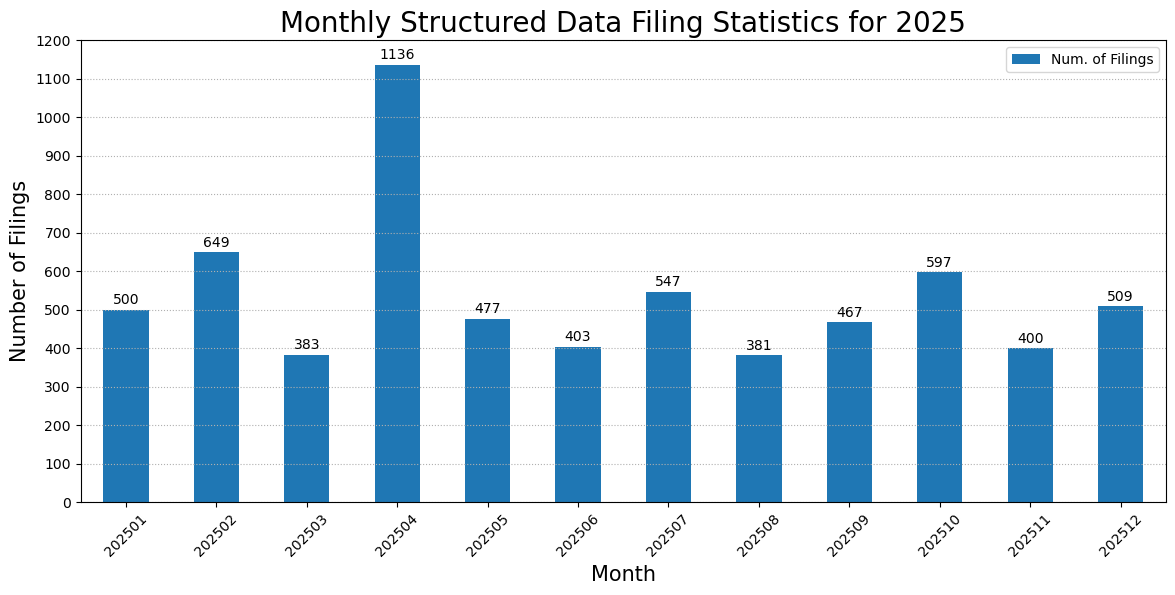

In [9]:
# Create a bar chart with month on x axis and number of filings on y axis
ax = filingsGroupedByMonth.plot(x='Month', y='Num. of Filings', kind='bar', figsize=(14,6))
# Set title and labels for x & y axes
plt.title('Monthly Structured Data Filing Statistics for 2025',fontsize=20)
plt.xlabel('Month', fontsize=15)
plt.ylabel('Number of Filings', fontsize=15)
plt.yticks(np.arange(0, 1201, step=100))
plt.xticks(rotation=45)
# Add counts on top of bars
ax.bar_label(ax.containers[0], padding=2)
plt.grid(axis='y', linestyle=':')
# Save the bar chart as a file in images folder
plt.savefig('images/MonthlyStats2025.jpg', bbox_inches='tight')
plt.show()